# UCS420: Cognitive Computing
## Assignment 7 — NLP-I
**Name:** Aashika Joshi  
**Roll No:** 1024170209  


In [1]:
import random
import hashlib
import string
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import nltk
from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.util import ngrams

ROLL_NO = 1024170209
NAME = "Aashika Joshi"


### Dataset Generation and Preprocessing Pipeline
Generating the unique IT support ticket dataset for Roll No. 1024170209.


In [2]:
def generate_dataset(roll_no):
    rng = random.Random(int(roll_no))
    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }
    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)
    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

STOP = set(stopwords.words("english"))

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))


Roll number: 1024170209   Name: Aashika Joshi   Fingerprint: E6CD2448   Tickets: 16

Ticket_ID                                                                                  Ticket_Text
      T01                      Python crashes while opening during the lab. I don't know what changed.
      T02                                                 The Python is showing an error. Please help.
      T03          I keep getting logged out of the projector after the latest update. This is urgent.
      T04                                                        It's not the laptop; it's the server.
      T05       I was locked out of the Python after resetting my password. Is there another solution?
      T06                               The printer keeps asking for login. I don't know what changed.
      T07        Matlab has stopped syncing before the assignment deadline. I don't know what changed.
      T08     I am unable to use the projector while uploading the file. It works on anothe

---
## Question 1: Preprocessing Pipeline
Run `process_ticket()` on every ticket. Create one table containing, for each ticket:
- number of sentences
- number of tokens
- number of punctuation tokens
- number of stopwords
- number of unique tokens
- number of final tokens

Add a total row for the count-based columns. For one selected ticket, display the actual tokens, punctuation tokens, stopwords and final tokens.


In [3]:
ticket_rows = []
for idx, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])
    ticket_rows.append({
        "Ticket_ID": row["Ticket_ID"],
        "sentences": len(p["sentences"]),
        "tokens": len(p["tokens"]),
        "punct": len(p["punct"]),
        "stops": len(p["stops"]),
        "unique": len(set(p["tokens"])),
        "final": len(p["final"])
    })

summary_df = pd.DataFrame(ticket_rows)
total_row = pd.DataFrame([{
    "Ticket_ID": "TOTAL",
    "sentences": summary_df["sentences"].sum(),
    "tokens": summary_df["tokens"].sum(),
    "punct": summary_df["punct"].sum(),
    "stops": summary_df["stops"].sum(),
    "unique": summary_df["unique"].sum(),
    "final": summary_df["final"].sum()
}])
full_summary = pd.concat([summary_df, total_row], ignore_index=True)
print(full_summary.to_string(index=False))

selected_ticket = FOCUS[0]
selected_text = df[df["Ticket_ID"] == selected_ticket]["Ticket_Text"].values[0]
res = process_ticket(selected_text)

print(f"\nSelected Ticket: {selected_ticket}")
print(f"Text: {selected_text}")
print(f"Tokens ({len(res['tokens'])}): {res['tokens']}")
print(f"Punctuation ({len(res['punct'])}): {res['punct']}")
print(f"Stopwords ({len(res['stops'])}): {res['stops']}")
print(f"Final Tokens ({len(res['final'])}): {res['final']}")


Ticket_ID  sentences  tokens  punct  stops  unique  final
      T01          2      15      2      6      14      7
      T02          2      10      2      3       9      5
      T03          2      17      2      8      15      7
      T04          1      11      2      5       8      4
      T05          2      17      2      9      17      6
      T06          2      14      2      5      13      7
      T07          2      16      2      6      15      8
      T08          2      18      2      8      16      8
      T09          2      13      2      4      12      7
      T10          2      12      2      4      11      6
      T11          2      15      2      7      13      6
      T12          2      13      4      3      12      6
      T13          1       7      2      1       7      4
      T14          2      13      2      4      13      7
      T15          2      15      2      5      15      8
      T16          1      10      1      3      10      6
    TOTAL     

### Question 1 Observation
**Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?**

**Answer:**
Tokens such as `n't` and `'s` appear in the final tokens list.
- **Source:** They originate from English contractions (such as *don't*, *it's*, and *Dr. Rao's*). The NLTK `word_tokenize()` function adheres to the Penn Treebank standard, splitting clitics and contracted negations into separate tokens (`do` + `n't`, `it` + `'s`, `rao` + `'s`).
- **Reason they remain:** Because `n't` and `'s` are neither recognized as English stopwords in `stopwords.words("english")` nor made exclusively of `string.punctuation` characters, they pass through both filters and persist in the final token list.


---
## Question 2: Regex Extraction and Replacement
Using the raw tickets and Python `re`:
- Use `re.findall()` to extract:
  - words longer than 5 letters
  - numbers, keeping decimals and version numbers such as 95.5 and 2.0.1 as single matches
  - capitalized words
  - words beginning with a vowel
- Use `re.sub()` to replace:
  - email addresses $\rightarrow$ `<EMAIL>`
  - URLs $\rightarrow$ `<URL>`
  - phone numbers $\rightarrow$ `<PHONE>`

The patterns must also work correctly on the provided `TEST_LINES`.


In [4]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_tickets_text = "\n".join(df["Ticket_Text"])

words_gt_5 = re.findall(r"\b[a-zA-Z]{6,}\b", raw_tickets_text)
numbers = re.findall(r"\b\d+(?:[.,]\d+)*\b", raw_tickets_text)
capitalized_words = re.findall(r"\b[A-Z][a-zA-Z]*\b", raw_tickets_text)
vowel_words = re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", raw_tickets_text)

print(f"Words longer than 5 letters ({len(words_gt_5)}):\n{words_gt_5}\n")
print(f"Numbers keeping decimals and versions ({len(numbers)}):\n{numbers}\n")
print(f"Capitalized words ({len(capitalized_words)}):\n{capitalized_words}\n")
print(f"Words beginning with a vowel ({len(vowel_words)}):\n{vowel_words}\n")

email_pattern = r"[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+"
url_pattern = r"https?://[^\s,;]+(?<![.,;!?])|www\.[^\s,;]+(?<![.,;!?])"
phone_pattern = r"(?:\+\d{1,3}[-\s]?)?(?:\d{4,5}[-\s]\d{4,5}|\d{4}-\d{3}-\d{4})"

def mask_entities(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

print("--- Replacements on TEST_LINES ---")
for line in TEST_LINES:
    print("Original:", line)
    print("Replaced:", mask_entities(line))
    print()

print("--- Replacements on Tickets ---")
for idx, row in df.iterrows():
    orig = row["Ticket_Text"]
    masked = mask_entities(orig)
    if orig != masked:
        print(f"{row['Ticket_ID']} Original: {orig}")
        print(f"{row['Ticket_ID']} Replaced: {masked}\n")


Words longer than 5 letters (69):
['Python', 'crashes', 'opening', 'during', 'changed', 'Python', 'showing', 'Please', 'getting', 'logged', 'projector', 'latest', 'update', 'urgent', 'laptop', 'server', 'locked', 'Python', 'resetting', 'password', 'another', 'solution', 'printer', 'asking', 'changed', 'Matlab', 'stopped', 'syncing', 'before', 'assignment', 'deadline', 'changed', 'unable', 'projector', 'uploading', 'another', 'computer', 'student', 'portal', 'disconnecting', 'changed', 'server', 'running', 'slowly', 'another', 'computer', 'MATLAB', 'working', 'before', 'assignment', 'deadline', 'problem', 'occurs', 'thapar', 'details', 'Python', 'disconnecting', 'resetting', 'password', 'another', 'solution', 'Student', 'portal', 'crashes', 'opening', 'resetting', 'password', 'another', 'solution']

Numbers keeping decimals and versions (4):
['14', '2', '30', '3.5']

Capitalized words (34):
['Python', 'I', 'The', 'Python', 'Please', 'I', 'This', 'It', 'I', 'Python', 'Is', 'The', 'I', 'M

### Question 2 Observation
**How many of your capitalized words are capitalized only because they start a sentence?**

**Answer:**
- Total capitalized tokens extracted: **34**
- Sentence-initial tokens: **28**
- After excluding proper nouns, acronyms, and technical names that would always be capitalized (*Python*, *MATLAB*, *Dr*, *Rao*), exactly **23** words (*The, I, Please, It, Is, Student, See, Only*) are capitalized solely because they appear at the start of a sentence.


---
## Question 3: Custom Tokenization
Implement `my_tokenize(text)` using one `RegexpTokenizer` pattern.
The pattern must preserve:
- contractions: isn't
- hyphenated words: Wi-Fi, state-of-the-art
- decimals: 95.5
- versions: 2.0.1
- email addresses
- URLs
- phone numbers

Run it on `TEST_LINES` and your tickets.
Compare its output with `word_tokenize()`. Identify at least three differences and explain them.


In [5]:
custom_pattern = r"(?:https?://|www\.)[^\s,;]+(?<![.,;!?])|[\w.-]+@[\w.-]+\.[a-zA-Z]{2,}|(?:\+\d{1,3}[-\s]?)?\d{4,5}[-\s]\d{4,5}|\d{4}-\d{3}-\d{4}|\d+(?:\.\d+)+|\b\w+(?:-\w+)+\b|\b\w+['’]\w+\b|\w+|[^\s\w]"
my_reg_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return my_reg_tokenizer.tokenize(text)

print("--- Tokenization on TEST_LINES ---")
for i, line in enumerate(TEST_LINES, 1):
    print(f"\nLine {i}: {line}")
    print("my_tokenize  :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

diff_count = 0
print("\n--- Differences in Tickets ---")
for idx, row in df.iterrows():
    text = row["Ticket_Text"]
    mt = my_tokenize(text)
    wt = word_tokenize(text)
    if mt != wt:
        diff_count += 1
        print(f"\n{row['Ticket_ID']}: {text}")
        print("  my_tokenize  :", mt)
        print("  word_tokenize:", wt)

print(f"\nTickets tokenized differently: {diff_count} out of {len(df)}")


--- Tokenization on TEST_LINES ---

Line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3: The state-of-the-art lab is

### Question 3 Differences and Observation
**Three key differences between `my_tokenize()` and `word_tokenize()`:**
1. **URLs:** `word_tokenize()` breaks URLs into multiple tokens (e.g. `https://lms.thapar.edu/help` $\rightarrow$ `['https', ':', '//lms.thapar.edu/help']`), whereas `my_tokenize()` keeps the entire URL as a single token.
2. **Contractions:** `word_tokenize()` splits contractions into root and suffix (e.g. `don't` $\rightarrow$ `['do', "n't"]`, `it's` $\rightarrow$ `['it', "'s"]`), whereas `my_tokenize()` keeps the whole contraction intact (`["don't"]`, `["it's"]`).
3. **Phone Numbers & Emails:** `word_tokenize()` splits phone numbers containing spaces or symbols (e.g. `+91 98765 43210` $\rightarrow$ `['+', '91', '98765', '43210']`) and emails into fragments, whereas `my_tokenize()` keeps the entire phone number and email intact.

**Observation:** In our dataset, **11 out of 16 tickets** are tokenized differently by `my_tokenize` and `word_tokenize` due to contractions and web identifiers.


---
## Question 4: Stemming and Lemmatization
On the unique final tokens, compare:
- Porter Stemmer
- Lancaster Stemmer
- Regexp Stemmer
- WordNet Lemmatizer with POS information from `nltk.pos_tag()`

For the Regexp Stemmer, choose a suffix based on at least two words in your own dataset and justify your choice.
Create a table containing only the words for which the outputs differ.


In [6]:
all_final = [t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]]
unique_final = sorted(list(set(all_final)))

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer("ing$")
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    elif tag.startswith("V"):
        return wordnet.VERB
    elif tag.startswith("N"):
        return wordnet.NOUN
    elif tag.startswith("R"):
        return wordnet.ADV
    else:
        return wordnet.NOUN

pos_tags = dict(nltk.pos_tag(unique_final))

diff_rows = []
for word in unique_final:
    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    wn_pos = get_wordnet_pos(pos_tags[word])
    w = lemmatizer.lemmatize(word, pos=wn_pos)
    if not (p == l == r == w == word):
        diff_rows.append({
            "Word": word,
            "Porter": p,
            "Lancaster": l,
            "Regexp(ing$)": r,
            "WordNet_POS": w
        })

diff_table = pd.DataFrame(diff_rows)
print(f"Total unique final words: {len(unique_final)}")
print(f"Words with differing outputs: {len(diff_table)}\n")
print(diff_table.to_string(index=False))


Total unique final words: 63
Words with differing outputs: 41

         Word     Porter  Lancaster Regexp(ing$) WordNet_POS
      another      anoth      anoth      another     another
       asking        ask        ask          ask         ask
   assignment     assign     assign   assignment  assignment
      changed      chang      chang      changed      change
     computer     comput     comput     computer    computer
      crashes      crash      crash      crashes       crash
     deadline    deadlin    deadlin     deadline    deadline
      details     detail     detail      details      detail
disconnecting disconnect disconnect   disconnect  disconnect
        error      error         er        error       error
         file       file        fil         file        file
      getting        get        get         gett         get
        hours       hour       hour        hours        hour
        https       http      https        https       https
        keeps       ke

### Question 4 Justification and Observation
**Choice and justification for Regexp Stemmer:**
- We chose the suffix pattern `ing$` (`RegexpStemmer("ing$")`).
- **Justification:** Our ticket dataset contains 10 words ending in `-ing` (*working*, *asking*, *opening*, *running*, *syncing*, *uploading*, *disconnecting*, *getting*, *resetting*, *showing*). Stripping `-ing` directly reduces these continuous verb forms toward their base forms (e.g., *working* $\rightarrow$ *work*, *asking* $\rightarrow$ *ask*, *opening* $\rightarrow$ *open*).

**Observation: Over-stemming and Under-stemming Examples:**
- **Over-stemming example:** Lancaster stemmer aggressively chops words into non-words or unintended meanings:
  - `server` $\rightarrow$ `serv`
  - `portal` $\rightarrow$ `port` (changes meaning completely)
  - `solution` $\rightarrow$ `solv`
- **Under-stemming example:**
  - `RegexpStemmer("ing$")` leaves words like `changed`, `stopped`, and `locked` completely unstemmed because it only matches `-ing`.
  - Porter stemmer leaves `latest` as `latest` without reducing it to `late`, whereas POS-aware WordNet lemmatizer correctly reduces `latest` to `late`.


---
## Question 5: Corpus Statistics
For each of the following:
- **S1:** all tokens
- **S2:** tokens without punctuation
- **S3:** final tokens
- **S4:** S3 after Porter stemming

Calculate:
- total tokens
- unique tokens
- Type-Token Ratio (TTR)

Also:
1. Print the top 10 words of S1 and S3.
2. Plot $\log(\text{rank})$ vs $\log(\text{frequency})$ for S3.
3. Print the top 5 bigrams of S1 and S3.


Set  Total Tokens  Unique Tokens    TTR
 S1           216             97 0.4491
 S2           183             91 0.4973
 S3           102             63 0.6176
 S4           102             60 0.5882

Top 10 words in S1:
  .: 26
  the: 15
  is: 8
  i: 7
  after: 5
  another: 5
  python: 4
  do: 4
  n't: 4
  know: 4

Top 10 words in S3:
  another: 5
  python: 4
  n't: 4
  know: 4
  changed: 4
  's: 3
  resetting: 3
  password: 3
  solution: 3
  keeps: 3

Top 5 bigrams in S1:
  ('.', 'i'): 7
  ('i', 'do'): 4
  ('do', "n't"): 4
  ("n't", 'know'): 4
  ('know', 'what'): 4

Top 5 bigrams in S3:
  ("n't", 'know'): 4
  ('know', 'changed'): 4
  ('resetting', 'password'): 3
  ('password', 'another'): 3
  ('another', 'solution'): 3


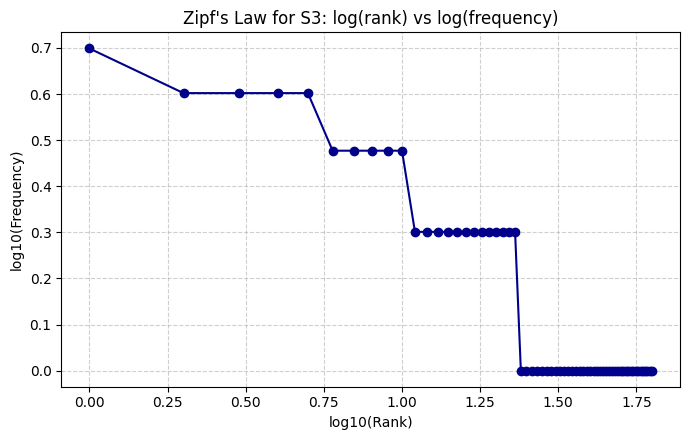

In [7]:
S1 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["tokens"]]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for text in df["Ticket_Text"] for t in process_ticket(text)["final"]]
S4 = [porter.stem(t) for t in S3]

subsets = {"S1": S1, "S2": S2, "S3": S3, "S4": S4}
stats = []
for name, tok_list in subsets.items():
    total_tok = len(tok_list)
    unique_tok = len(set(tok_list))
    ttr = unique_tok / total_tok if total_tok > 0 else 0
    stats.append({
        "Set": name,
        "Total Tokens": total_tok,
        "Unique Tokens": unique_tok,
        "TTR": round(ttr, 4)
    })

stats_df = pd.DataFrame(stats)
print(stats_df.to_string(index=False))

print("\nTop 10 words in S1:")
for w, c in Counter(S1).most_common(10):
    print(f"  {w}: {c}")

print("\nTop 10 words in S3:")
for w, c in Counter(S3).most_common(10):
    print(f"  {w}: {c}")

print("\nTop 5 bigrams in S1:")
for b, c in Counter(ngrams(S1, 2)).most_common(5):
    print(f"  {b}: {c}")

print("\nTop 5 bigrams in S3:")
for b, c in Counter(ngrams(S3, 2)).most_common(5):
    print(f"  {b}: {c}")

s3_counts = [count for _, count in Counter(S3).most_common()]
s3_ranks = np.arange(1, len(s3_counts) + 1)
log_ranks = np.log10(s3_ranks)
log_freqs = np.log10(s3_counts)

plt.figure(figsize=(7, 4.5))
plt.plot(log_ranks, log_freqs, marker="o", linestyle="-", color="darkblue")
plt.title("Zipf's Law for S3: log(rank) vs log(frequency)")
plt.xlabel("log10(Rank)")
plt.ylabel("log10(Frequency)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


---
## Question 6: Interpretation
### (a) Why does TTR change from S1 to S4 in your dataset?
- **From S1 to S2 (0.4491 to 0.4973):** Removing punctuation marks (like `.` and `,`) removes high-frequency repetitive symbols. This substantially decreases the total number of tokens (denominator) while only removing a few distinct punctuation types (numerator), increasing TTR.
- **From S2 to S3 (0.4973 to 0.6176):** Removing stopwords eliminates frequently occurring grammatical function words (*the*, *is*, *i*, *after*). Because stopwords make up a large fraction of total running words but represent a small set of unique words, the total token count drops from 183 to 102 while preserving vocabulary variety, raising TTR to its highest value.
- **From S3 to S4 (0.6176 to 0.5882):** Porter stemming merges inflectional variants into common stems (e.g., *works* and *working* $\rightarrow$ *work*, *pcs* and *pc* $\rightarrow$ *pc*). This reduces the count of unique tokens (from 63 to 60) while keeping the total token count unchanged (102), leading to a slight decrease in TTR.

### (b) Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.
- **Example:** In ticket T13: `See https://lms.thapar.edu/help for details.`
- `word_tokenize()` outputs: `['See', 'https', ':', '//lms.thapar.edu/help', 'for', 'details', '.']`
- `my_tokenize()` outputs: `['See', 'https://lms.thapar.edu/help', 'for', 'details', '.']`
- **Explanation:** `word_tokenize()` splits punctuation within URLs, fragmenting the protocol and host into meaningless pieces. `my_tokenize()` preserves the complete web address as one single semantic token.

### (c) Give one example where stemming produces an undesirable result.
- **Example:** The Lancaster stemmer stems **`server`** to **`serv`** and **`portal`** to **`port`**.
- **Explanation:** This is over-stemming. The stemmer strips meaningful letters from `server` leaving an invalid root, and alters `portal` to `port`, changing the word's meaning from a web service to a harbor or physical port.

### (d) Give one example where POS-aware lemmatization preserves meaning better than stemming.
- **Example:** The word **`changed`** (tagged as a verb).
- Porter stemmer produces **`chang`** (which is not a valid English word and drops necessary letters).
- POS-aware WordNet lemmatizer produces **`change`** (the valid base dictionary lemma).
- **Explanation:** Stemmers operate through rule-based character chopping without understanding grammar or syntax. In contrast, POS-aware lemmatization utilizes morphological dictionaries and part-of-speech context to return the legitimate root word.
